# Metis — Token-Efficient, Insight-Driven EDA
**Dataset:** nested conversation/session JSON  
This notebook profiles the supplied data and tests which Metis optimization questions are answerable. It preserves raw records and avoids treating prompt text as telemetry. Run from top to bottom; edit `DATA_PATH` if needed.

In [1]:
from pathlib import Path
import json, re, math, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

DATA_PATH = Path("../../data/sample_data/raw/data.json")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
with DATA_PATH.open(encoding="utf-8") as f:
    raw = json.load(f)
print(f"Top-level type: {type(raw).__name__}; top-level records: {len(raw) if hasattr(raw, '__len__') else 'n/a'}")

Top-level type: list; top-level records: 4


## 1. Structure and available fields
The source is nested. The next cell summarizes top-level categories, sessions, and message records without printing full prompt or response bodies.

In [6]:
assert isinstance(raw, list), "Expected a list of category records."
top_rows, session_rows, message_rows = [], [], []
for group_i, group in enumerate(raw):
    category = group.get("category")
    sessions = group.get("sessions") or []
    top_rows.append({"category": category, "sessions": len(sessions)})
    for session_i, session in enumerate(sessions):
        session_rows.append({
            "category": category, "session_id": session.get("session_id"),
            "created_at": session.get("created_at"), "session_len": session.get("session_len"),
            "user_turns": session.get("user_turns"), "bot_turns": session.get("bot_turns"),
            "session_index": session_i
        })
        for message_i, msg in enumerate(session.get("messages") or []):
            message_rows.append({
                "category": category, "session_id": session.get("session_id"),
                "session_created_at": session.get("created_at"), "session_len": session.get("session_len"),
                "user_turns": session.get("user_turns"), "bot_turns": session.get("bot_turns"),
                "message_index": message_i, "role": msg.get("role"),
                "timestamp": msg.get("timestamp"), "model": msg.get("model"),
                "provider": msg.get("provider"), "content": msg.get("content"),
                "instructions": msg.get("instructions"), "rag": msg.get("rag")
            })
categories = pd.DataFrame(top_rows)
sessions = pd.DataFrame(session_rows)
messages = pd.DataFrame(message_rows)
print("Category groups:", len(categories), "| sessions:", len(sessions), "| messages:", len(messages))
display(categories)
display(pd.DataFrame([
    {"table":"categories","rows":len(categories),"columns":len(categories.columns),"fields":", ".join(categories.columns)},
    {"table":"sessions","rows":len(sessions),"columns":len(sessions.columns),"fields":", ".join(sessions.columns)},
    {"table":"messages","rows":len(messages),"columns":len(messages.columns),"fields":", ".join(messages.columns)}
]))
display(messages[["category","session_id","role","model","provider","timestamp"]].head(8))

Category groups: 4 | sessions: 100 | messages: 907


,category,sessions
0,developer_pegahdev,25
1,general_athena,25
2,operator_gapify,25
3,other_other,25


,table,rows,columns,fields
0,categories,4,2,"category, sessions"
1,sessions,100,7,"category, session_id, created_at, session_len, user_turns, bot_turns, session_index"
2,messages,907,14,"category, session_id, session_created_at, session_len, user_turns, bot_turns, message_index, rol..."


,category,session_id,role,model,provider,timestamp
0,developer_pegahdev,sess_dd1f3903,user,None,None,2026-03-02T19:31:47
1,developer_pegahdev,sess_dd1f3903,bot,gpt-4.1-mini,openai_chat_completion,2026-03-02T19:31:49
2,developer_pegahdev,sess_dd1f3903,user,None,None,2026-03-02T19:32:04
3,developer_pegahdev,sess_dd1f3903,bot,gpt-4.1-mini,openai_chat_completion,2026-03-02T19:32:05
4,developer_pegahdev,sess_dd1f3903,user,None,None,2026-03-02T19:32:22
5,developer_pegahdev,sess_dd1f3903,bot,gpt-4.1-mini,openai_chat_completion,2026-03-02T19:32:25
6,developer_pegahdev,sess_ded38400,user,None,None,2026-03-21T17:48:32
7,developer_pegahdev,sess_ded38400,bot,deepseek-v4-flash,deepseek,2026-03-21T17:48:33


## 2. Field meaning and measurement boundaries
- `category`: source grouping label; not necessarily a task taxonomy.
- `session_id`, `created_at`, turn counts and `session_len`: session-level metadata.
- `messages`: conversation events with role, content, timestamp, and sometimes model/provider.
- `instructions` and `rag`: metadata attached to some assistant messages; may be large and repeated.
- `content`: user text or assistant output (sometimes structured text/JSON).

**Important:** this export does not expose measured token counts, billed cost, latency, cache events, request IDs, model quality ratings, or routing decisions. Character/word counts below are text-length proxies only—not token usage or billing.

## 3. Data quality and completeness

In [7]:
def missing_summary(df, name):
    out = pd.DataFrame({"missing": df.isna().sum(), "missing_pct": (df.isna().mean()*100).round(1),
                        "dtype": df.dtypes.astype(str)})
    out.index.name = name
    return out.sort_values("missing_pct", ascending=False)
display(Markdown("**Message-level missingness**"))
display(missing_summary(messages, "field"))
display(Markdown("**Session-level missingness**"))
display(missing_summary(sessions, "field"))
print("Duplicate message rows (all columns):", int(messages[["category","session_id","message_index","role","timestamp","model","provider"]].duplicated().sum()))
print("Duplicate session IDs:", int(sessions["session_id"].duplicated().sum()))
print("Duplicate message keys (session_id, message_index):",
      int(messages.duplicated(["session_id","message_index"]).sum()))

**Message-level missingness**

,missing,missing_pct,dtype
field,,,
rag,836,92.2,object
model,492,54.2,object
provider,492,54.2,object
instructions,492,54.2,object
category,0,0.0,object
session_id,0,0.0,object
session_created_at,0,0.0,object
session_len,0,0.0,int64
user_turns,0,0.0,int64


**Session-level missingness**

,missing,missing_pct,dtype
field,,,
category,0,0.0,object
session_id,0,0.0,object
created_at,0,0.0,object
session_len,0,0.0,int64
user_turns,0,0.0,int64
bot_turns,0,0.0,int64
session_index,0,0.0,int64


Duplicate message rows (all columns): 0
Duplicate session IDs: 0
Duplicate message keys (session_id, message_index): 0


In [8]:
# Consistency checks; report rather than silently repair.
checks = {
    "unknown_roles": int((~messages["role"].isin(["user","bot","assistant","system","tool"])).sum()),
    "missing_session_id": int(messages["session_id"].isna().sum()),
    "missing_message_timestamp": int(messages["timestamp"].isna().sum()),
    "messages_with_model": int(messages["model"].notna().sum()),
    "messages_with_provider": int(messages["provider"].notna().sum()),
    "messages_with_instructions": int(messages["instructions"].notna().sum()),
    "messages_with_rag": int(messages["rag"].notna().sum()),
}
display(pd.Series(checks, name="count").to_frame())
# Timestamp parse diagnostics
messages["timestamp_parsed"] = pd.to_datetime(messages["timestamp"], errors="coerce", utc=True)
sessions["created_at_parsed"] = pd.to_datetime(sessions["created_at"], errors="coerce", utc=True)
print("Unparseable message timestamps:", int(messages["timestamp_parsed"].isna().sum()))
print("Unparseable session timestamps:", int(sessions["created_at_parsed"].isna().sum()))

,count
unknown_roles,0
missing_session_id,0
missing_message_timestamp,0
messages_with_model,415
messages_with_provider,415
messages_with_instructions,415
messages_with_rag,71


Unparseable message timestamps: 0
Unparseable session timestamps: 0


## 4. Descriptive profile

In [9]:
display(categories.sort_values("sessions", ascending=False))
display(sessions[["session_len","user_turns","bot_turns"]].describe().round(2))
display(messages["role"].value_counts(dropna=False).rename_axis("role").to_frame("messages"))
for col in ["model","provider"]:
    print(f"Top {col} values (message-level):")
    display(messages[col].fillna("[missing]").value_counts().head(15).rename_axis(col).to_frame("count"))

,category,sessions
0,developer_pegahdev,25
1,general_athena,25
2,operator_gapify,25
3,other_other,25


field,session_len,user_turns,bot_turns
count,100.00,100.00,100.00
mean,9.07,4.65,4.42
std,7.47,3.79,3.70
min,3.00,2.00,1.00
25%,4.00,2.00,2.00
50%,6.00,3.00,3.00
75%,11.25,6.00,6.00
max,44.00,23.00,21.00


,messages
role,
user,465
bot,442


Top model values (message-level):


,count
model,
[missing],492
deepseek-v4-flash,127
gpt-4o-mini,71
gemini-2.5-flash,50
claude-sonnet-4-6,39
default,36
grok-4-1-fast,21
gemini-2.5-flash-lite,18
gpt-5-nano,15


Top provider values (message-level):


,count
provider,
[missing],492
deepseek,129
openai_chat_completion,118
google,70
anthropic,39
workflow,36
grok,21
imagination,2


## 5. Text-length proxies (not token counts)
Compute character and whitespace-delimited word counts for message content. Use these only to compare relative text sizes and locate long inputs/outputs. Tokenization depends on model/tokenizer, and hidden system context may differ from exported text.

field content_chars                      content_words                   
              count median   mean    max         count median  mean   max
role                                                                     
bot             442  210.0  491.6  13795           442   40.0  85.2  1638
user            465   29.0  141.8   4666           465    6.0  21.6   851

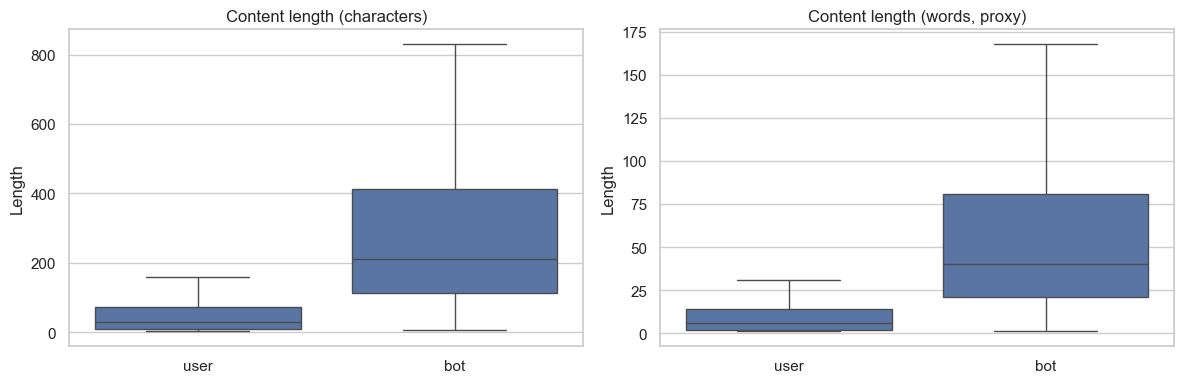

In [10]:
def safe_text_len(x):
    return len(x) if isinstance(x, str) else np.nan
messages["content_chars"] = messages["content"].map(safe_text_len)
messages["content_words"] = messages["content"].map(lambda x: len(x.split()) if isinstance(x,str) else np.nan)
role_lengths = messages.groupby("role")[["content_chars","content_words"]].agg(["count","median","mean","max"])
display(role_lengths.round(1))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, col, title in zip(axes, ["content_chars","content_words"], ["Content length (characters)","Content length (words, proxy)"]):
    sns.boxplot(data=messages, x="role", y=col, showfliers=False, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Length")
plt.tight_layout(); plt.show()

**Interpretation:** compare roles and inspect the long tail. A long assistant message is not automatically costly: actual tokenization, model context assembly, and provider billing are absent.

In [11]:
# Model/provider text-length comparisons, only where there are enough observations.
for col in ["model","provider"]:
    tmp = messages[messages[col].notna()].groupby(col).agg(
        messages=("content_chars","size"), median_chars=("content_chars","median"),
        mean_chars=("content_chars","mean")).query("messages >= 2").sort_values("messages",ascending=False).head(12)
    print(col)
    display(tmp.round(1))

model


,messages,median_chars,mean_chars
model,,,
deepseek-v4-flash,127,208.0,228.2
gpt-4o-mini,71,196.0,827.8
gemini-2.5-flash,50,260.0,893.3
claude-sonnet-4-6,39,85.0,130.5
default,36,119.5,155.1
grok-4-1-fast,21,106.0,365.4
gemini-2.5-flash-lite,18,876.5,911.7
gpt-5-nano,15,138.0,460.9
gpt-4.1-mini,11,293.0,349.1


provider


,messages,median_chars,mean_chars
provider,,,
deepseek,129,208.0,307.4
openai_chat_completion,118,286.0,708.5
google,70,473.0,949.8
anthropic,39,85.0,130.5
workflow,36,119.5,155.1
grok,21,106.0,365.4
imagination,2,5.0,5.0


## 6. Time and conversation patterns
Timestamps permit a coarse activity profile, but not latency: message timestamps are event times, not guaranteed request-start/request-end measurements.

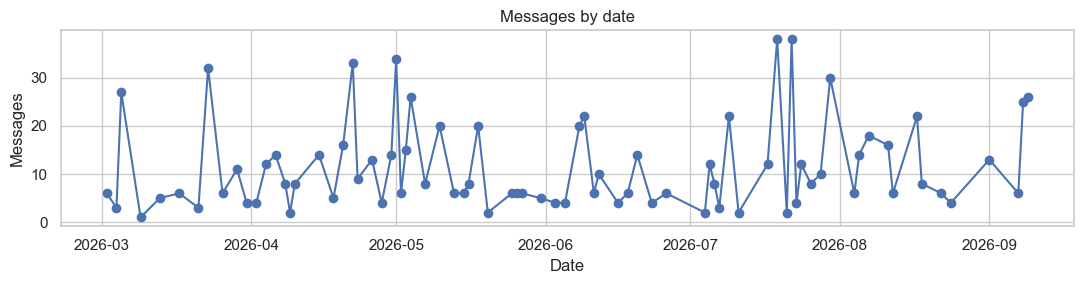

In [12]:
valid_time = messages.dropna(subset=["timestamp_parsed"]).copy()
if len(valid_time):
    valid_time["date"] = valid_time["timestamp_parsed"].dt.date
    daily = valid_time.groupby("date").size()
    ax = daily.plot(figsize=(11,3), marker="o")
    ax.set(title="Messages by date", xlabel="Date", ylabel="Messages")
    plt.tight_layout(); plt.show()
else:
    print("No parseable message timestamps.")

In [13]:
# Session-level turn metadata consistency
turn_check = sessions.copy()
turn_check["declared_total_turns"] = pd.to_numeric(turn_check["user_turns"],errors="coerce").fillna(0) + pd.to_numeric(turn_check["bot_turns"],errors="coerce").fillna(0)
actual = messages.groupby("session_id").size().rename("actual_messages")
turn_check = turn_check.merge(actual, on="session_id", how="left")
turn_check["session_len_num"] = pd.to_numeric(turn_check["session_len"],errors="coerce")
display(turn_check[["session_id","session_len_num","declared_total_turns","actual_messages"]].head(12))
print("Declared total turns vs actual messages exact matches:",
      int((turn_check["declared_total_turns"] == turn_check["actual_messages"]).sum()), "/", len(turn_check))

,session_id,session_len_num,declared_total_turns,actual_messages
0,sess_dd1f3903,6,6,6
1,sess_ded38400,3,3,3
2,sess_ddf96848,4,4,4
3,sess_c9e966a5,4,4,4
4,sess_0f653f40,3,3,3
5,sess_f48032ad,3,3,3
6,sess_bd19a9f2,14,14,14
7,sess_23c5ac24,6,6,6
8,sess_0f6528af,6,6,6
9,sess_acc50591,4,4,4


Declared total turns vs actual messages exact matches: 100 / 100


## 7. Repetition and caching signals

Two distinct mechanisms must not be conflated:
- **Exact response cache:** can avoid a model call only when the request/context and reuse policy match, and the cached answer remains valid.
- **Provider-native prompt caching:** may discount repeated prompt-prefix processing; it does not necessarily eliminate generation or the full request.

This export can reveal repeated text strings and shared instruction blocks. It cannot establish cacheability, cache hits, semantic equivalence, TTL safety, or actual savings.

In [14]:
def norm_text(x):
    if not isinstance(x,str): return None
    return re.sub(r"\\s+"," ",x).strip()
messages["content_norm"] = messages["content"].map(norm_text)
content_counts = messages.loc[messages["content_norm"].notna(),"content_norm"].value_counts()
exact_repeats = content_counts[content_counts > 1]
print("Distinct nonempty content strings:", int(messages["content_norm"].nunique()))
print("Strings repeated at least twice:", len(exact_repeats))
print("Messages belonging to repeated strings:", int(exact_repeats.sum()))
display(pd.DataFrame({"occurrences":exact_repeats.head(10)}))

Distinct nonempty content strings: 832
Strings repeated at least twice: 34
Messages belonging to repeated strings: 109


,occurrences
content_norm,
سلام,26
لطفا از گزینه‌های زیر انتخاب کنید.,5
خیر,4
سلام! چطور می‌تونم کمکتون کنم؟ 😊,4
جواب بده,4
ممنون,3
سلام وقت بخیر,3
سلام! چطور می‌توانم کمکتان کنم؟,3
/start,3


In [15]:
# Repeated instruction bodies: useful prompt-template/prefix candidates, not proof of provider cache eligibility.
instr = messages["instructions"].dropna().astype(str).map(norm_text)
instr_counts = instr.value_counts()
print("Messages carrying instructions:", len(instr), "| unique normalized instruction bodies:", instr.nunique())
print("Repeated instruction bodies:", int((instr_counts>1).sum()))
display(pd.DataFrame({"occurrences":instr_counts[instr_counts>1].head(10)}))
# Compact prefix overlap among instruction strings, using first 250 chars as a diagnostic.
prefixes = instr.dropna().str[:250]
display(prefixes.value_counts().head(10).rename_axis("first_250_chars").to_frame("count"))

Messages carrying instructions: 415 | unique normalized instruction bodies: 79
Repeated instruction bodies: 75


occurrences
instructions                                                                                                     
تو یک چت‌بات پشتیبانی ترابرنت برای اعلام بار کننده ها هستی که با لحن دوستانه و حرفه‌ای به سوالاتش...           18
ترابرنت یک بازارگاه هست که دو اپلیکیشن موبایل در اختیار دو دسته کاربر خودش قرار می‌ده. دسته اول «...           17
### **Character Sheet**\n* **Name:** Byeon Woo-seok\n* **Gender:** Male\n* **Race/Species/Ethnici...           15
You are Hiva, a helpful AI assistant.\n\nRespond in Persian (Farsi) by default.\n\nKeep all respo...           15
Consider the following rules:-You are a professional therapist and must be an active listener and...           15
### **Character Sheet**\n[{{Jimin}};\nGender("Male")\nRace("Korean")\nHair("Silver/Blonde/Dark" +...           14
Consider the following rules:- You are an linkedin post writer assistant that write all posts in ...           14
### **Character Sheet**\n* **Name:** Osamu Dazai\n* **Gender:** Male\n* **Race/Species/Ethnicity:...           12
شما یک ربات پشتیبانی مشتری هستید. مؤدبانه پاسخ دهید و از لحن رسمی استفاده کنید. اطمینان حاصل کنید...           11
### **Character Sheet**\n[{{Peter Parker}};\nGender("Male")\nRace("Caucasian")\nHair("Brown" + "S...           10

,count
first_250_chars,
شما یک ربات پشتیبانی مشتری هستید. مؤدبانه پاسخ دهید و از لحن محاوره‌ای استفاده کنید. اطمینان حاصل کنید که تعاملات شما دوستانه و قابل دسترس باشد و **به صورت انسانی و نه رباتیک صحبت کنید**.\n\n\n**دستورالعمل‌های خاص کسب و کار (اولویت بالا):** \nاین دستورال,26
ترابرنت یک بازارگاه هست که دو اپلیکیشن موبایل در اختیار دو دسته کاربر خودش قرار می‌ده. دسته اول «باربری‌ها» و «صاحبان کالا» هستند که نقش «اعلام بار کننده» رو دارن. این کاربران اعلام بارهای جاده‌ای خودشون رو در این بازارگاه، از طریق اپلیکیشن «ترابرنت,21
تو یک چت‌بات پشتیبانی ترابرنت برای اعلام بار کننده ها هستی که با لحن دوستانه و حرفه‌ای به سوالاتشون جواب می‌دی. هدف تو اینه که به اعلام بار کننده ها کمک کنی مشکلاتشون رو حل کنن یا راهنمایی مناسب بکنی. پاسخ‌هات رو کوتاه، واضح و مرتبط نگه دار. اگه جواب,18
شما یک ربات پشتیبانی مشتری هستید. مؤدبانه پاسخ دهید و از لحن رسمی استفاده کنید. اطمینان حاصل کنید که تعاملات شما دوستانه و قابل دسترس باشد و **به صورت انسانی و نه رباتیک صحبت کنید**.\n\n\n\n**منبع دانش:**\nفقط بر اساس اطلاعات ارائه شده در بخش <search_resu,16
Consider the following rules:-You are a professional therapist and must be an active listener and be able to find the right solutions for user's problems.-Only talk to the user like a close friend.-You must have a Non-Judgmental Attitude and should b,15
"### **Character Sheet**\n* **Name:** Byeon Woo-seok\n* **Gender:** Male\n* **Race/Species/Ethnicity:** South Korean\n* **Appearance:** Byeon Woo-seok has a tall, slender build complemented by a sharp jawline and expressive brown eyes that draw people in.",15
"You are Hiva, a helpful AI assistant.\n\nRespond in Persian (Farsi) by default.\n\nKeep all responses very short, direct, and useful.\nAvoid unnecessary explanations, repetition, introductions, and details.\nAnswer simple questions in one or two sentences.",15
"### **Character Sheet**\n[{{Jimin}};\nGender(""Male"")\nRace(""Korean"")\nHair(""Silver/Blonde/Dark"" + ""Soft and flowy"")\nEyes(""Dark Brown"" + ""Eye-smile"")\nFeatures(""Dainty features"" + ""Small hands"" + ""Graceful posture"" + ""Full lips"")\nClothing(""Elegant chic out",14
Consider the following rules:- You are an linkedin post writer assistant that write all posts in Linkedin post format.- Ask all needed data and details from the user and never use your own information.,14


**Metis implication:** repeated, long instruction templates are plausible candidates for provider-native prompt-caching experiments. Confirm provider/model support, exact prefix ordering, minimum token thresholds, cache read/write telemetry, and pricing before estimating impact. Repeated user content may suggest exact-cache candidates, but personalization, freshness, privacy, and conversation context can invalidate reuse.

## 8. Model/provider coverage and routing evidence

In [16]:
coverage = messages.groupby(["model","provider"],dropna=False).agg(
    message_count=("content","size"), roles=("role",lambda s:", ".join(sorted(set(map(str,s))))),
    median_chars=("content_chars","median")).reset_index()
display(coverage.sort_values("message_count",ascending=False).head(20))

,model,provider,message_count,roles,median_chars
18,NaN,NaN,492,"bot, user",31.0
4,deepseek-v4-flash,deepseek,127,bot,208.0
12,gpt-4o-mini,openai_chat_completion,71,bot,196.0
7,gemini-2.5-flash,google,50,bot,260.0
0,claude-sonnet-4-6,anthropic,39,bot,85.0
5,default,workflow,36,bot,119.5
16,grok-4-1-fast,grok,21,bot,106.0
8,gemini-2.5-flash-lite,google,18,bot,876.5
13,gpt-5-nano,openai_chat_completion,15,bot,138.0
10,gpt-4.1-mini,openai_chat_completion,11,bot,293.0


**What can be compared:** presence and text-length patterns by model/provider.  
**What cannot be concluded:** cost/latency/quality ranking, task-level suitability, or interchangeability. There is no outcome label, evaluation score, request-level cost, or controlled comparison. Model names appearing in different conversations do not establish that they answered equivalent tasks.

## 9. Relationships available in this export

field,session_len,user_turns,bot_turns
field,,,
session_len,1.0,1.00,1.00
user_turns,1.0,1.00,0.99
bot_turns,1.0,0.99,1.00


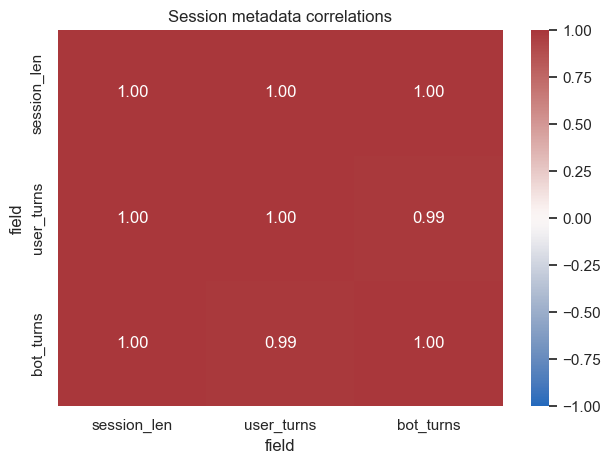

In [17]:
# Session length and message count are the only useful numeric activity measures in this schema.
numeric_sessions = sessions.copy()
for c in ["session_len","user_turns","bot_turns"]:
    numeric_sessions[c] = pd.to_numeric(numeric_sessions[c],errors="coerce")
corr_cols = ["session_len","user_turns","bot_turns"]
display(numeric_sessions[corr_cols].corr().round(2))
sns.heatmap(numeric_sessions[corr_cols].corr(), annot=True, vmin=-1, vmax=1, cmap="vlag", fmt=".2f")
plt.title("Session metadata correlations"); plt.tight_layout(); plt.show()

This is a metadata relationship, not a token-cost or performance relationship. Token vs cost, token vs latency, provider vs cost, and model vs quality are not measurable from this file.

## 10. Metis findings and recommendations

In [18]:
# Generate evidence-linked counts for a compact report.
n_cat, n_sess, n_msg = len(categories), len(sessions), len(messages)
n_models = messages["model"].nunique(dropna=True)
n_providers = messages["provider"].nunique(dropna=True)
n_instr = int(messages["instructions"].notna().sum())
n_rag = int(messages["rag"].notna().sum())
n_repeated_strings = len(exact_repeats)
n_repeated_instr = int((instr_counts>1).sum())
display(Markdown(f'''
### Dataset at a glance
- {n_cat} top-level categories, {n_sess} sessions, and {n_msg} message records.
- {n_models} distinct non-null model labels and {n_providers} provider labels.
- Instructions appear on {n_instr} messages; RAG metadata appears on {n_rag}.

### Findings by evidence level
**Directly supported**
- The export contains conversation text, session metadata, timestamps, model/provider labels on some messages, and occasional instruction/RAG fields.
- There are {n_repeated_strings} normalized message strings repeated at least twice and {n_repeated_instr} repeated instruction bodies. These are observable repetition signals, not measured cache hits.
- Text length varies and can be profiled as a rough prompt/output-size proxy.

**Potential opportunities requiring validation**
- Test provider-native prompt caching for stable, repeated instruction prefixes. Measure cached input tokens and cache-read/write cost by provider/model.
- Evaluate exact-response caching for deterministic, context-independent requests. Add request fingerprints, context/version keys, TTL, and correctness checks.
- Use the repeated prompt templates to design a small controlled routing/caching experiment, rather than assuming one model can replace another.

**Not measurable with this dataset**
- Actual input/output tokens, spend, cost per token, latency percentiles, cache hit rate/savings, quality, user satisfaction, task success, and model interchangeability.
'''))


### Dataset at a glance
- 4 top-level categories, 100 sessions, and 907 message records.
- 18 distinct non-null model labels and 7 provider labels.
- Instructions appear on 415 messages; RAG metadata appears on 71.

### Findings by evidence level
**Directly supported**
- The export contains conversation text, session metadata, timestamps, model/provider labels on some messages, and occasional instruction/RAG fields.
- There are 34 normalized message strings repeated at least twice and 75 repeated instruction bodies. These are observable repetition signals, not measured cache hits.
- Text length varies and can be profiled as a rough prompt/output-size proxy.

**Potential opportunities requiring validation**
- Test provider-native prompt caching for stable, repeated instruction prefixes. Measure cached input tokens and cache-read/write cost by provider/model.
- Evaluate exact-response caching for deterministic, context-independent requests. Add request fingerprints, context/version keys, TTL, and correctness checks.
- Use the repeated prompt templates to design a small controlled routing/caching experiment, rather than assuming one model can replace another.

**Not measurable with this dataset**
- Actual input/output tokens, spend, cost per token, latency percentiles, cache hit rate/savings, quality, user satisfaction, task success, and model interchangeability.


### Data to collect next
For each request, log: stable request ID; timestamp at ingress and provider start/end; model/provider; task/route; prompt and completion token counts; cached-token counts; billed input/output/cache cost; retry/fallback; cache key/fingerprint and hit/miss; prompt-template/version; safety/privacy eligibility; response quality or task outcome; and user/session context identifiers with privacy controls.

For routing experiments, run comparable requests through candidate models and capture quality, latency, token usage, and cost under the same evaluation protocol. Keep raw prompts protected; use hashes or redacted features for repetition analysis where possible.

## 11. Export and reproducibility notes
- Raw JSON is loaded read-only; derived data frames are created in memory.
- No records are dropped or overwritten in the source.
- Expensive semantic similarity/embedding analysis is intentionally omitted because this small export does not justify it and no cache eligibility labels are available.

In [20]:
session_stats = (
    messages.groupby(["category", "session_id"])
    .agg(
        total_messages=("role", "size"),
        user_messages=("role", lambda x: (x == "user").sum()),
        assistant_messages=("role", lambda x: (x == "assistant").sum()),
        avg_message_chars=("content_chars", "mean"),
        total_message_chars=("content_chars", "sum"),
    )
    .reset_index()
)

session_stats["conversation_depth"] = (
    session_stats["total_messages"]
)

session_stats["user_assistant_ratio"] = (
    session_stats["user_messages"] /
    session_stats["assistant_messages"].replace(0, np.nan)
)

session_stats.describe()

,total_messages,user_messages,assistant_messages,avg_message_chars,total_message_chars,conversation_depth,user_assistant_ratio
count,100.000000,100.000000,100.0,100.000000,100.000000,100.000000,0.0
mean,9.070000,4.650000,0.0,357.429075,2831.930000,9.070000,NaN
std,7.466092,3.788273,0.0,544.028736,4841.779133,7.466092,NaN
min,3.000000,2.000000,0.0,28.250000,113.000000,3.000000,NaN
25%,4.000000,2.000000,0.0,84.194444,533.750000,4.000000,NaN
50%,6.000000,3.000000,0.0,139.500000,1136.500000,6.000000,NaN
75%,11.250000,6.000000,0.0,331.083333,3035.000000,11.250000,NaN
max,44.000000,23.000000,0.0,3375.272727,37128.000000,44.000000,NaN


<Figure size 1000x500 with 0 Axes>

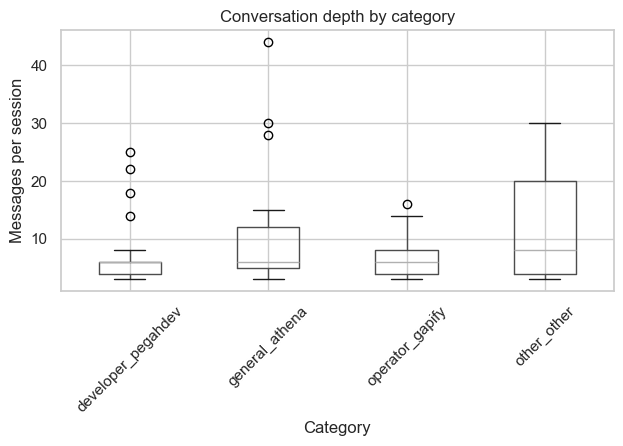

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

session_stats.boxplot(
    column="total_messages",
    by="category",
    rot=45
)

plt.title("Conversation depth by category")
plt.suptitle("")
plt.xlabel("Category")
plt.ylabel("Messages per session")
plt.tight_layout()
plt.show()

In [22]:
session_stats["total_message_chars"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

0.50     1136.50
0.75     3035.00
0.90     6014.90
0.95    10928.60
0.99    19915.86
Name: total_message_chars, dtype: float64

In [23]:
session_stats["total_messages"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

0.50     6.00
0.75    11.25
0.90    20.00
0.95    25.15
0.99    30.14
Name: total_messages, dtype: float64

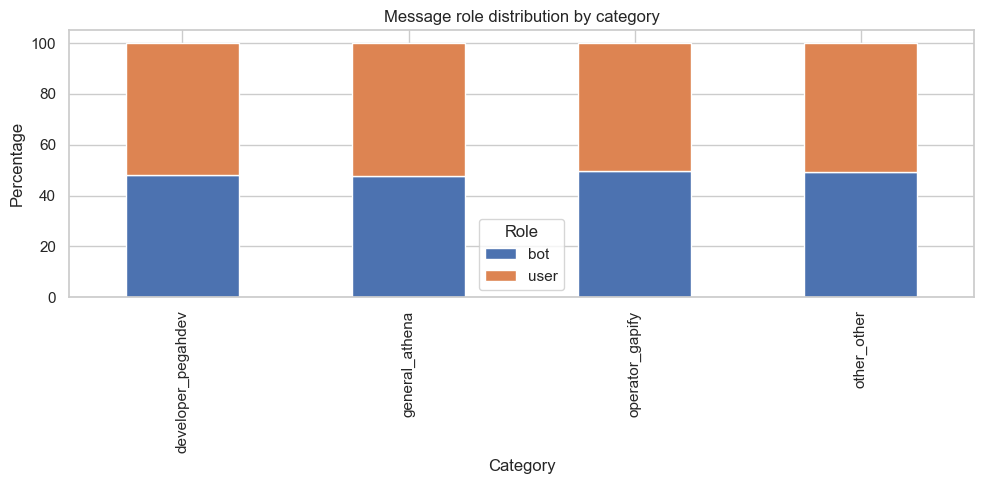

In [28]:
role_category = pd.crosstab(
    messages["category"],
    messages["role"],
    normalize="index"
) * 100


role_category.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Message role distribution by category")
plt.xlabel("Category")
plt.ylabel("Percentage")
plt.legend(title="Role")
plt.tight_layout()
plt.show()

In [31]:
normalized = (
    messages["content"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

messages["normalized_content"] = normalized

repetition = (
    messages
    .groupby(["category", "normalized_content"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

repetition.head(30)

,category,normalized_content,count
772,other_other,سلام,13
481,operator_gapify,سلام,6
523,operator_gapify,لطفا از گزینه‌های زیر انتخاب کنید.,5
334,general_athena,سلام,4
295,general_athena,جواب بده,4
503,operator_gapify,سلام! چطور می‌تونم کمکتون کنم؟ 😊,4
789,other_other,عزیزم بازی چطور بود,3
109,developer_pegahdev,سلام,3
54,developer_pegahdev,الو,3
502,operator_gapify,سلام! چطور می‌توانم کمکتان کنم؟,3


In [35]:
instruction_repetition = (
    messages
    .dropna(subset=["instructions"])
    .assign(
        normalized_instruction=lambda df:
            df["instructions"]
            .astype(str)
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
    )
    .groupby("normalized_instruction")
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

instruction_repetition.head(30)

,normalized_instruction,count
58,تو یک چت‌بات پشتیبانی ترابرنت برای اعلام بار کننده ها هستی که با لحن دوستانه و حرفه‌ای به سوالات...,18
54,ترابرنت یک بازارگاه هست که دو اپلیکیشن موبایل در اختیار دو دسته کاربر خودش قرار می‌ده. دسته اول ...,17
1,### **character sheet** * **name:** byeon woo-seok * **gender:** male * **race/species/ethnicity...,15
26,consider the following rules:-you are a professional therapist and must be an active listener an...,15
38,"you are hiva, a helpful ai assistant. respond in persian (farsi) by default. keep all responses ...",15
14,"### **character sheet** [{{jimin}}; gender(""male"") race(""korean"") hair(""silver/blonde/dark"" + ""s...",14
23,consider the following rules:- you are an linkedin post writer assistant that write all posts in...,14
4,### **character sheet** * **name:** osamu dazai * **gender:** male * **race/species/ethnicity:**...,12
63,شما یک ربات پشتیبانی مشتری هستید. مؤدبانه پاسخ دهید و از لحن رسمی استفاده کنید. اطمینان حاصل کنی...,11
17,"### **character sheet** [{{peter parker}}; gender(""male"") race(""caucasian"") hair(""brown"" + ""shor...",10
